# Day 5 · Senses: Sight — A forecast you can see
### #30DayMapChallenge 2026 · ECMWF IFS simulated satellite imagery · Map by Emma Pidduck

The theme is **Sight** — so this is how the *model* sees. What looks like a satellite
photograph of Earth is nothing of the kind: it is the **ECMWF IFS forecast**, rendered as a
geostationary imager would see it. A **six-day forecast** of the whole Meteosat disc, drawn in
the infrared — the swirl of every cyclone, the cold anvils of tropical convection over Africa,
the dark warm Sahara — for an atmosphere that **hasn't happened yet**.

The IFS doesn't only predict the fields forecasters read off charts. Through a radiative-transfer
model it also produces **synthetic satellite images**: the brightness temperature each channel of
each imager *would* measure, given the model's clouds, water vapour and surface. That lets a
forecaster put the model's "view" straight next to the real satellite and see, at a glance, where
the forecast is right — and it means the model can render a satellite image days before the
satellite takes one.

## Method

- Retrieve the IFS **simulated satellite image** product (`type=ssd`) from **MARS**: the
  **Meteosat-10 (0°E) SEVIRI** infrared **window channel at 10.8 µm** (channel 9), as *cloudy
  (all-sky) brightness temperature* — ECMWF parameter `clbt` (`260510`), in kelvin.
- Take the **T+144 h** step from the 1 Nov 2026 00 UTC run — a six-day forecast.
- Draw it in the true **Meteosat geostationary geometry** (`cartopy` `Geostationary`, sub-satellite
  point 0°N 0°E), on the house white, with an enhanced-IR ramp: **cold cloud tops white, warm
  surface deep indigo**.

Why the infrared window? Because 10.8 µm sees cloud-top *temperature* — so it works by day and
night, and the coldest, highest cloud tops (deep convection, frontal cloud) stand out brightest.
It is the classic "satellite image" look.

## Licence & attribution

ECMWF's simulated satellite imagery (`type=ssd`) is an **operational product** — normally accessed
by licensed users through MARS and dissemination under ECMWF's **service / charge model**, and
**not** part of the free open-data release.

For this notebook, the three brightness-temperature fields are shared as a **one-off under
[CC-BY-4.0](https://creativecommons.org/licenses/by/4.0/)**, so the map is fully reproducible — you
can run it end to end from the small sample in `data/`. Any further or operational use of the `ssd`
product still goes through ECMWF's normal service model.

> © ECMWF, licensed **CC-BY-4.0** for this one-off sample · source www.ecmwf.int. Included to show
> what the IFS can *already* do — and to make the quiet case that synthetic imagery would be a
> natural candidate for opening. See
> [simulated satellite images](https://www.ecmwf.int/en/forecasts/documentation-and-support/simulated-satellite-images).

## Tools

| Tool | Role |
|---|---|
| **MARS** (`mars`, or [`ecmwf-api-client`](https://github.com/ecmwf/ecmwf-api-client)) | retrieve the `ssd` product (licensed) |
| [`earthkit-data`](https://earthkit-data.readthedocs.io) · `cfgrib` | read the brightness-temperature GRIB |
| `numpy` · `cartopy` · `matplotlib` | geostationary projection, enhanced-IR render |

To pull **fresh** data you need **ECMWF MARS access** (on an ECMWF platform, save the request below
and run `mars request.req`; off-site, a full MARS licence can use the web API). You don't need it to
run this notebook, though — the three fields shown are bundled in `data/` as a CC-BY-4.0 sample.

In [1]:
# Run once if needed (uncomment):
#!pip install ecmwf-api-client earthkit-data cfgrib cartopy matplotlib

In [2]:
import os, warnings
import numpy as np
import xarray as xr
import matplotlib.pyplot as plt
import matplotlib.patheffects as pe
from matplotlib.colors import LinearSegmentedColormap, to_rgba
import cartopy.crs as ccrs
import cartopy.feature as cfeature
warnings.filterwarnings("ignore")

plt.rcParams["font.family"] = "sans-serif"
plt.rcParams["font.sans-serif"] = ["Avenir Next", "Helvetica Neue", "Arial", "DejaVu Sans"]
BG, INK, MUT = "#ffffff", "#15213a", "#6b7580"

### Configuration

One satellite, one channel, one forecast step for the hero. The full product spans **12 SEVIRI
channels, two imagers and every step to T+240 h** — change `CHANNEL` to 5 for the 6.2 µm
water-vapour view, or `STEP_IDX` to 0 for the analysis-time image.

In [3]:
GRIB = "data/day05_ssd_ir108.grib"
STEP_IDX = 2                 # 0,1,2  ->  forecast T+0 / +72 / +144 h
VMIN, VMAX = 205, 300        # K: coldest convective tops -> warm surface
IDENT, INSTR, CHANNEL = 57, 207, 9    # Meteosat-10 (satNo 57), SEVIRI (207), IR 10.8 µm

## Retrieve from MARS

The native MARS request used here (slimmed to the hero field). The **full** product would set
`channel=1/2/3/4/5/6/7/8/9/10/11/14`, `ident=57/71`, `instrument=210/207` and
`step=0/3/6/.../240`, with `param=260510` (cloudy / all-sky) and `260512` (clear-sky) brightness
temperature.

```
retrieve, class=od, stream=oper, expver=1, type=ssd,
  date=2026-11-01, time=00,
  ident=57, instrument=207, channel=9,
  param=260510, step=0/72/144,
  grid=0.1/0.1, area=75/-75/-75/75,
  target="data/day05_ssd_ir108.grib"
```

In [4]:
os.makedirs("data", exist_ok=True)
if not os.path.exists(GRIB):
    # Needs ECMWF MARS access — this is licensed operational data, NOT open data.
    # On an ECMWF platform, save the request above to request.req and run:  mars request.req
    # Off-site, with a full MARS licence, via the web API:
    from ecmwfapi import ECMWFService
    ECMWFService("mars").execute({
        "class": "od", "stream": "oper", "expver": "1", "type": "ssd",
        "date": "2026-11-01", "time": "00",
        "ident": "57", "instrument": "207", "channel": "9",
        "param": "260510", "step": "0/72/144",
        "grid": "0.1/0.1", "area": "75/-75/-75/75",
    }, GRIB)

## Read & pick the forecast step

In [5]:
ds = xr.open_dataset(GRIB, engine="cfgrib")
da = ds["clbt"]                              # cloudy (all-sky) brightness temperature, K
if "step" in da.dims:
    da = da.isel(step=STEP_IDX)
bt  = da.values
lon = ds.longitude.values; lat = ds.latitude.values
run = str(ds.time.values)[:10]
vt  = str(da.valid_time.values)[:16].replace("T", " ") + " UTC"
fh  = int(ds.step.values[STEP_IDX] / np.timedelta64(1, "h"))
print(f"run {run} 00 UTC   forecast T+{fh}h   valid {vt}   BT {np.nanmin(bt):.1f} to {np.nanmax(bt):.1f} K")

run 2026-11-01 00 UTC   forecast T+144h   valid 2026-11-07 00:00 UTC   BT 194.0 to 302.6 K


### Colour — enhanced infrared (the operational look)

Greyscale for the scene — warm surface dark, cloud white, just like a classic IR image — with the
**coldest cloud tops** (deep convection, below ~235 K) enhanced through **cyan → blue → violet**, so
the most vigorous storms stand out. This is the convention operational "enhanced IR" products use.

It is the one map in the series that **trades strict colourblind-safety for fidelity** to the real
satellite look: the colour break at the cold end is deliberately *not* luminance-monotonic, and the
check below shows exactly that. (For a CVD-safe alternative, swap in a single-hue ramp.)

In [6]:
CMAP = LinearSegmentedColormap.from_list("irenh", [
    (0.00, "#f0e2ff"), (0.08, "#7b1fa2"), (0.16, "#1f4fb0"), (0.26, "#17b0c4"),
    (0.37, "#f3fdff"), (0.44, "#ffffff"), (0.62, "#c6c6c6"), (0.80, "#7a7a7a"), (1.00, "#1c1c1c")])
rgb = np.array([to_rgba(CMAP(t))[:3] for t in np.linspace(0, 1, 256)])
lum = 0.2126*rgb[:,0] + 0.7152*rgb[:,1] + 0.0722*rgb[:,2]
mono = (np.diff(lum) <= 1e-3).all() or (np.diff(lum) >= -1e-3).all()
print("enhanced-IR ramp — luminance-monotonic:", bool(mono), "(False by design: coloured cold tops)")

enhanced-IR ramp — luminance-monotonic: False (False by design: coloured cold tops)


## Render — the Meteosat disc

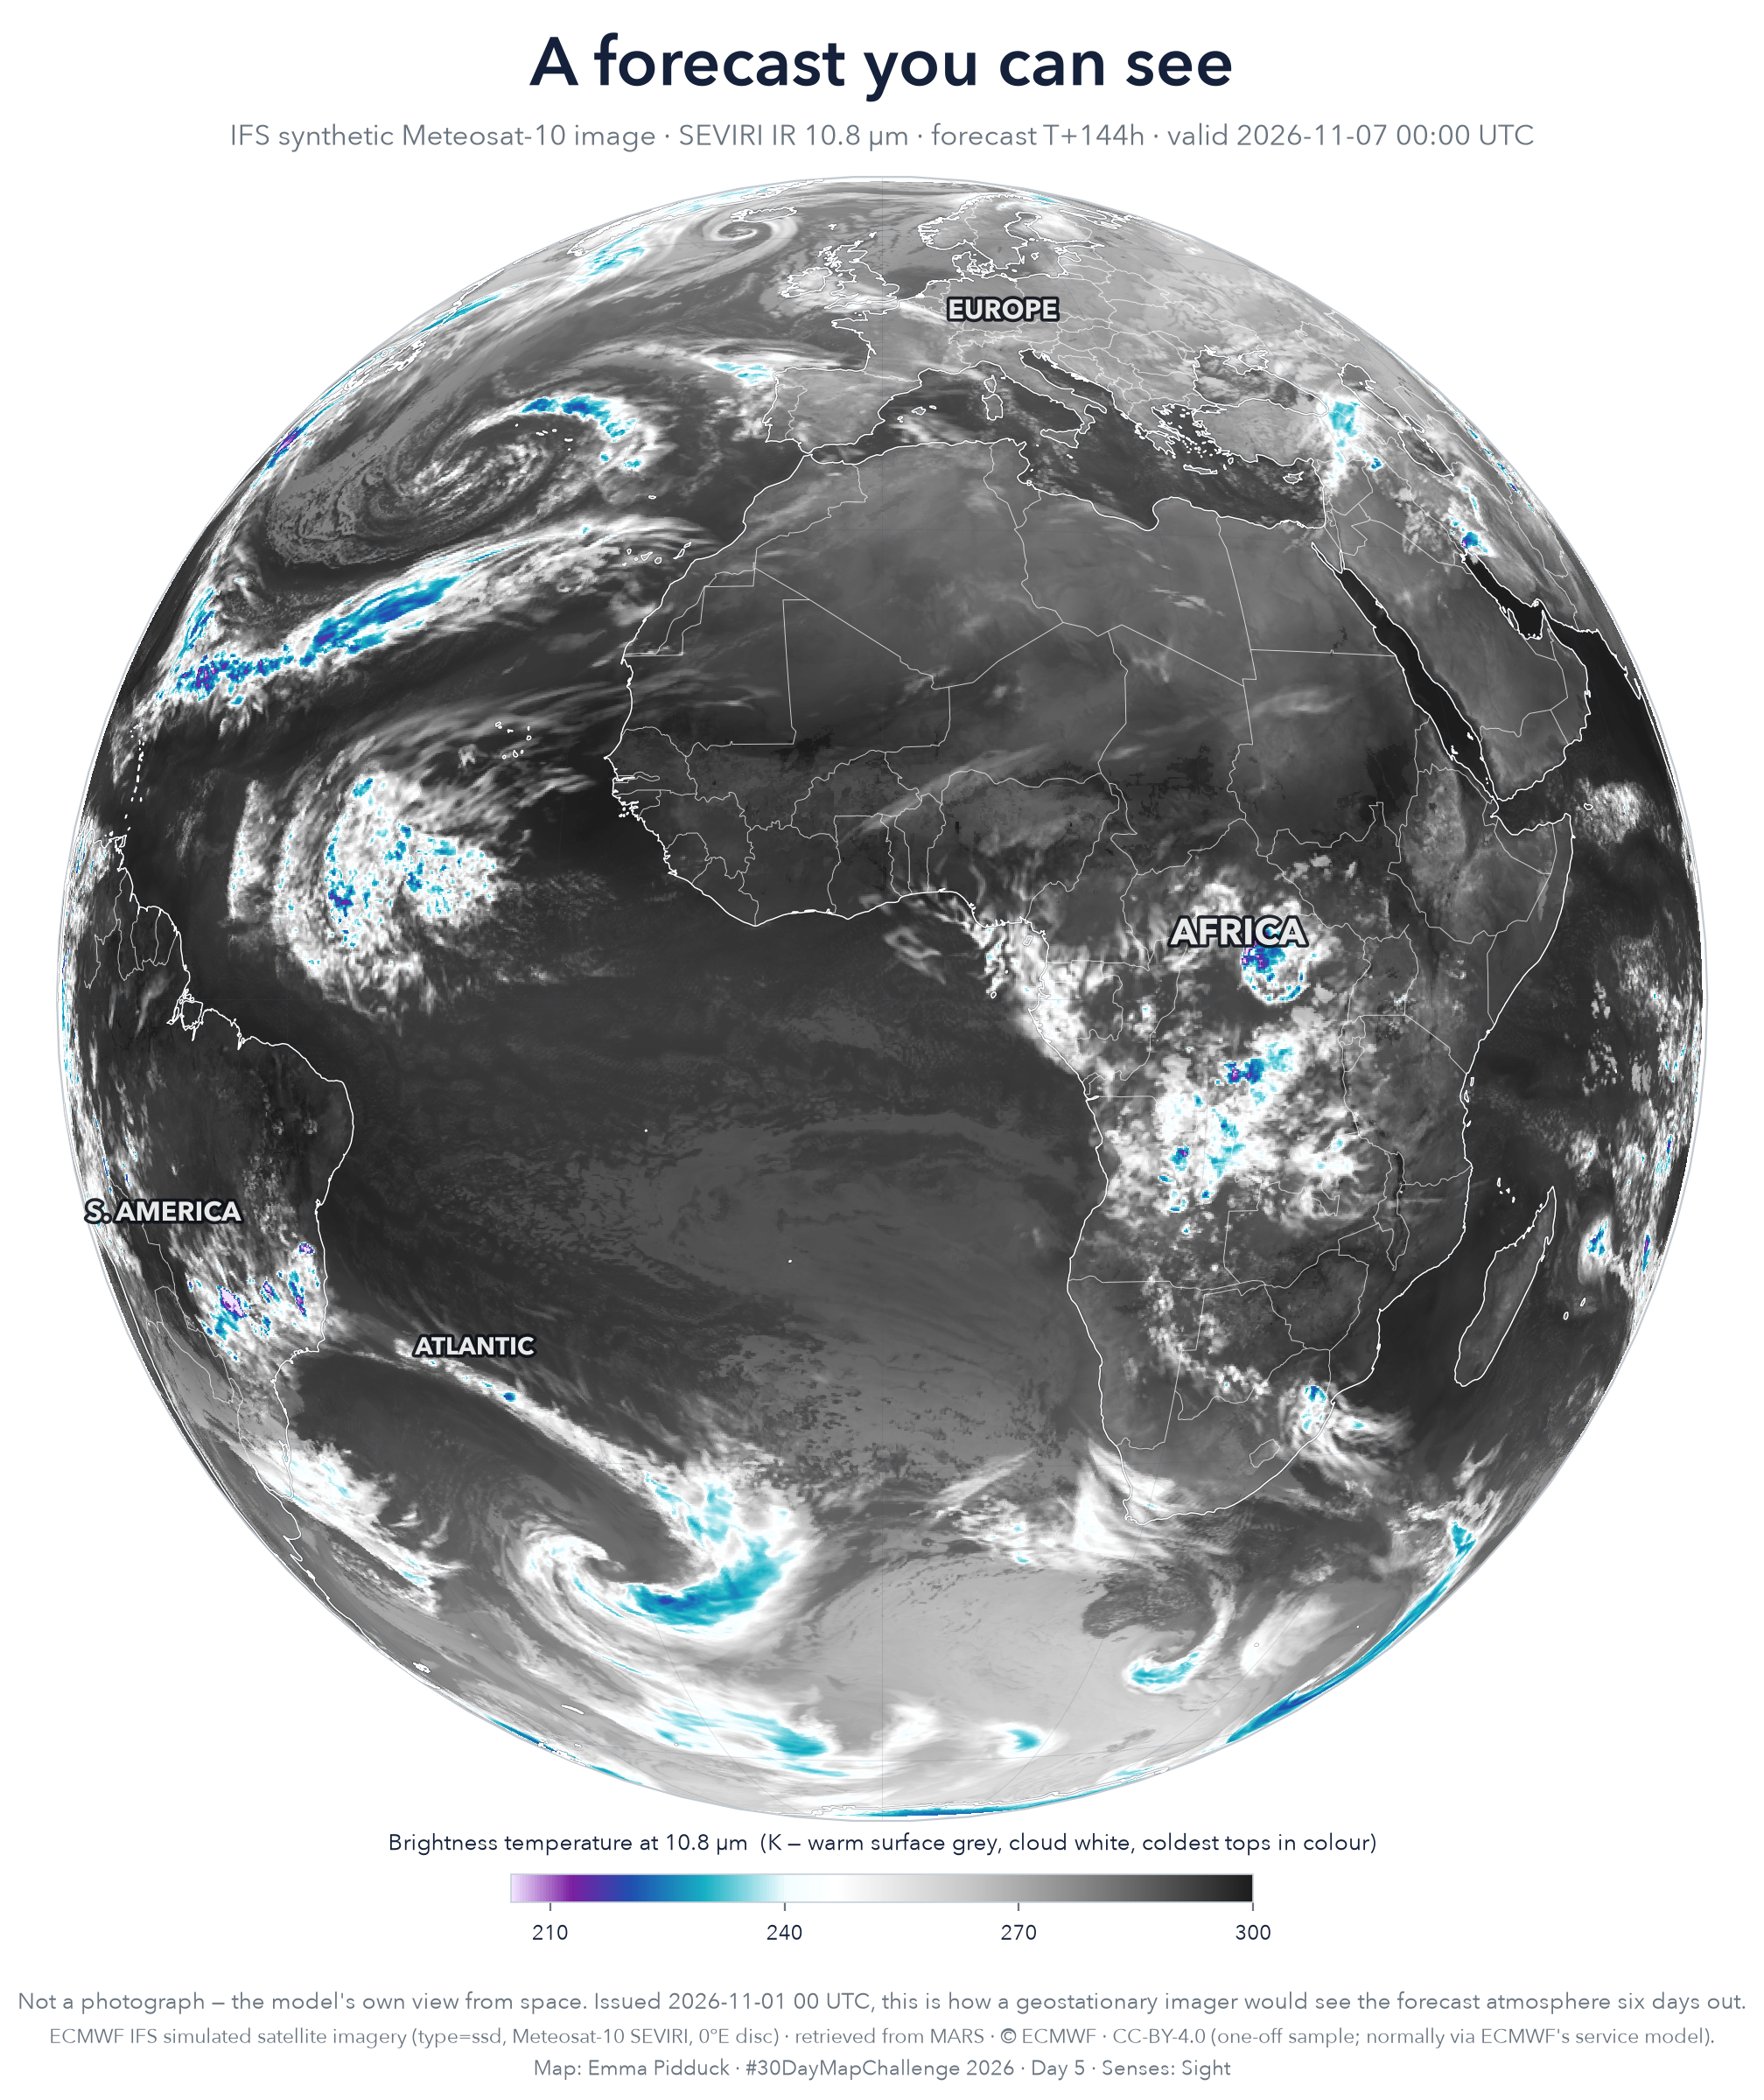

In [7]:
proj = ccrs.Geostationary(central_longitude=0, satellite_height=35785831)
tp = dict(transform=ccrs.PlateCarree())
fig = plt.figure(figsize=(10.6, 12.2), dpi=200); fig.patch.set_facecolor(BG)
ax = fig.add_axes([0.04, 0.15, 0.92, 0.77], projection=proj)
ax.set_global()
im = ax.pcolormesh(lon, lat, bt, cmap=CMAP, vmin=VMIN, vmax=VMAX, shading="auto", zorder=1, **tp)
ax.gridlines(color="#3650712e", linewidth=0.3, zorder=2)                 # thin globe graticule
# crisp WHITE country/coast boundaries, backed by a faint dark edge so they read over cloud and surface
ax.add_feature(cfeature.COASTLINE.with_scale("50m"), edgecolor="#0d1420", linewidth=1.1, alpha=0.35, zorder=3)
ax.add_feature(cfeature.COASTLINE.with_scale("50m"), edgecolor="#ffffff", linewidth=0.55, zorder=4)
ax.add_feature(cfeature.BORDERS.with_scale("50m"), edgecolor="#ffffff", linewidth=0.35, alpha=0.75, zorder=4)
ax.spines["geo"].set_edgecolor("#c3c9d0"); ax.spines["geo"].set_linewidth(0.8)

# continent labels for orientation (haloed white, subtle)
_lab = [pe.withStroke(linewidth=2.6, foreground="#0c1018")]
for name, lo, la, fs in [("EUROPE", 12, 50, 11), ("AFRICA", 22, 4, 15),
                         ("S. AMERICA", -56, -14, 11), ("ATLANTIC", -28, -22, 10)]:
    ax.text(lo, la, name, transform=ccrs.PlateCarree(), ha="center", va="center",
            color="#ffffff", fontsize=fs, fontweight="bold", alpha=0.9, zorder=6, path_effects=_lab)

cax = fig.add_axes([0.30, 0.112, 0.40, 0.013])
cb = fig.colorbar(im, cax=cax, orientation="horizontal", ticks=[210, 240, 270, 300])
cb.set_label("Brightness temperature at 10.8 µm  (K — warm surface grey, cloud white, coldest tops in colour)",
             color=INK, fontsize=9.3, labelpad=10)
cb.ax.xaxis.set_label_position("top")
cb.ax.xaxis.set_tick_params(color=MUT, labelsize=8.5); plt.setp(plt.getp(cb.ax, "xticklabels"), color=INK)
cb.outline.set_edgecolor("#c7d0d8"); cb.outline.set_linewidth(0.6)

fig.text(0.5, 0.963, "A forecast you can see", ha="center", color=INK, fontsize=28,
         fontfamily=["Avenir Next Demi Bold", "Arial", "DejaVu Sans"])
fig.text(0.5, 0.935, f"IFS synthetic Meteosat-10 image · SEVIRI IR 10.8 µm · forecast T+{fh}h · valid {vt}",
         ha="center", color=MUT, fontsize=12)
fig.text(0.5, 0.062, f"Not a photograph — the model's own view from space. Issued {run} 00 UTC, this is how a geostationary imager would see the forecast atmosphere six days out.",
         ha="center", color=MUT, fontsize=9.3)
fig.text(0.5, 0.046, "ECMWF IFS simulated satellite imagery (type=ssd, Meteosat-10 SEVIRI, 0°E disc) · retrieved from MARS · © ECMWF · CC-BY-4.0 (one-off sample; normally via ECMWF's service model).",
         ha="center", color=MUT, fontsize=8.3)
fig.text(0.5, 0.031, "Map: Emma Pidduck · #30DayMapChallenge 2026 · Day 5 · Senses: Sight",
         ha="center", color=MUT, fontsize=8.5)
fig.savefig("day05_sight_ssd.png", facecolor=BG, bbox_inches="tight")
plt.show()

## Bonus — rolling through the forecast

The same retrieval, asked for **every 6 hours out to T+120 h** (21 steps) instead of three, makes a
short animation: **five days of forecast weather**, drawn as the satellite would see it, rolling past
in a few seconds. Watch the Atlantic cyclones spin up and track, the ITCZ convection over Africa
pulse with the day–night cycle, and the cloud-free Sahara darken each night.

![Rolling IFS synthetic Meteosat-10 IR — five-day forecast](day05_ssd_rolling.gif)

*Built with the same code, looping over the forecast steps. The 21-field GRIB is larger, so it isn't
bundled — re-run the MARS request with the full `step=0/6/.../120` list to regenerate.*

## Note

This is a genuine forecast product, not a toy. ECMWF runs a radiative-transfer model (RTTOV) on
the IFS fields to produce the brightness temperature each satellite channel would observe — so the
synthetic image carries the model's clouds, humidity and surface into the same space a real
satellite image lives in. Forecasters use it to compare like with like: the model's "sight"
against the satellite's.

Two things stand out here. First, it's **six days ahead** — the satellite can only ever show *now*;
the model shows a plausible *then*. Second, it's **global and channel-flexible**: the IFS can render
the view for an imager, a channel, or a vantage point that no real satellite currently covers —
useful wherever observations are sparse.

The data isn't open — but the capability is striking, and (this being a personal experiment) it's
worth saying out loud that synthetic imagery would be a natural thing to open up.

**Saved:** `day05_sight_ssd.png` — ready to post.

*Day 2 Lines · Day 6 Vintage · Day 12 Power · Day 20 Hexagons · Day 22 Projections · Day 26 Water ·
Day 27 New tool · Day 28 Feeling.*